# asses the history of runs


In [43]:
import sys
print(sys.executable)


import pandas as pd
%matplotlib inline

import matplotlib
print("backend:", matplotlib.get_backend())
import matplotlib.pyplot as plt

import corner
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np


/home/kandrych/venvs/obriy311/bin/python
backend: inline


In [44]:



df_original=pd.read_csv("//fred/oz061/kandrych/smac/1_akke_2zones_wider_tapered/dubrulle/sed_interf_pdi_alma_stages/smac_results/trials.csv")
results_dir="/fred/oz061/kandrych/smac/1_akke_2zones_wider_tapered/dubrulle/sed_interf_pdi_alma_stages/smac_results/after_optimisation/"
Path(results_dir).mkdir(parents=True, exist_ok=True)

exclude = {"config_id", "seed", "budget", "cost", "time", "status", 
           'distance_pc', "zone_1_Rref", 'additional_info'}
#Because I did not yet figured out how to deal with additional info column, I will drop it for now. It is not needed for the optimisation anyway.
df = df_original.drop(columns=['additional_info'])

param_cols = [c for c in df.columns if c not in exclude]
print(param_cols)

df


['alpha_viscosity', 'disk_Rmid', 'disk_pa', 'disk_total_dust_mass', 'dust_settling', 'inclination', 'zone_1_Rin', 'zone_1_edge', 'zone_1_flaring_exp', 'zone_1_scale_height', 'zone_1_species_1_Vmax', 'zone_1_species_1_aexp', 'zone_1_species_1_amax', 'zone_1_species_1_amin', 'zone_1_species_1_component_2_optical_indices_file', 'zone_1_species_1_component_2_volume_fraction_iron', 'zone_1_species_1_porosity', 'zone_1_surface_density_exp', 'zone_1_type', 'zone_2_-gamma_exp', 'zone_2_Rc', 'zone_2_Rout', 'zone_2_Rref', 'zone_2_edge', 'zone_2_flaring_exp', 'zone_2_scale_height', 'zone_2_surface_density_exp', 'zone_2_type']


,alpha_viscosity,disk_Rmid,disk_pa,disk_total_dust_mass,distance_pc,dust_settling,inclination,zone_1_Rin,zone_1_Rref,zone_1_edge,...,zone_2_flaring_exp,zone_2_scale_height,zone_2_surface_density_exp,zone_2_type,config_id,seed,budget,cost,time,status
0,0.0100,11.529296,22,0.000978,1220.0,2,2,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.386063,2,1079,1819988010,1.0,1.609415e+01,96.522935,1
1,0.1000,11.739519,22,0.000926,1220.0,2,5,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.698170,2,855,1819988010,1.0,1.650627e+01,104.119671,1
2,0.1000,10.259817,22,0.000864,1220.0,2,2,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.442795,2,579,1819988010,1.0,1.668873e+01,94.585641,1
3,0.0100,17.701930,17,0.001198,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.567500,2,1214,1819988010,1.0,1.673140e+01,173.118121,1
4,0.0100,11.976679,22,0.001053,1220.0,2,5,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.205729,2,774,1819988010,1.0,1.703275e+01,95.467718,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.1000,16.388592,41,0.002914,1220.0,2,6,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-2.286542,2,1545,1819988010,9.0,1.000000e+99,88.311047,1
1996,0.0001,24.723939,111,0.005582,1220.0,2,22,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-3.945804,2,1546,1819988010,9.0,1.000000e+99,88.792223,1
1997,0.0100,17.957232,14,0.015087,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.557184,2,1547,1819988010,9.0,1.000000e+99,79.000258,1
1998,0.0100,17.991735,16,0.001274,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.465885,2,1523,1819988010,9.0,1.000000e+99,231.189556,1


### Best configs table (at max budget)

In [45]:
top = df[df["budget"] == df["budget"].max()].nsmallest(20, "cost")
print("Top 20 max budget trials:")

top.to_csv(results_dir + "top20_maxbudget.csv", index=False)
display(top)


Top 20 max budget trials:


,alpha_viscosity,disk_Rmid,disk_pa,disk_total_dust_mass,distance_pc,dust_settling,inclination,zone_1_Rin,zone_1_Rref,zone_1_edge,...,zone_2_flaring_exp,zone_2_scale_height,zone_2_surface_density_exp,zone_2_type,config_id,seed,budget,cost,time,status
1552,0.01,19.044252,20,0.001565,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.565449,2,985,1819988010,9.0,325.883644,2224.253275,1
1553,0.01,18.920636,20,0.000910,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.622359,2,1270,1819988010,9.0,328.452614,2271.252615,1
1554,0.01,17.887828,20,0.001086,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.581351,2,1170,1819988010,9.0,331.585892,2195.478544,1
1555,0.01,17.696866,19,0.001207,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.565449,2,1162,1819988010,9.0,336.539848,2336.869521,1
1556,0.01,18.786920,20,0.001010,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.375642,2,1141,1819988010,9.0,337.692113,2133.784677,1
1557,0.01,18.893864,20,0.001716,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.572674,2,1119,1819988010,9.0,340.043189,2347.140712,1
1558,0.01,17.991735,20,0.001274,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.565449,2,1041,1819988010,9.0,341.495234,2290.626904,1
1559,0.01,18.893864,20,0.001201,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.602397,2,1224,1819988010,9.0,341.938545,2182.843920,1
1560,0.01,18.899641,20,0.001372,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.572674,2,1048,1819988010,9.0,347.090262,2399.967571,1
1561,0.01,18.873097,20,0.000960,1220.0,2,0,7.2,7.2,0,...,zone_1_flaring_exp,zone_1_scale_height,-1.599915,2,1222,1819988010,9.0,349.227274,2227.767588,1


### Crashed runs inspection

In [46]:
df["status"] = np.where((df["cost"]==1e99) | (df["cost"]==df["cost"].max()), "Crashed", "Success")
#df.loc[df['cost'] == df['cost'].max(), 'cost'] = 1e99


crashed_trials=df[df["status"]=="Crashed"]
successful_trials=df[df["status"]=="Success"]

crash_rate = len(crashed_trials) / len(df)
print('Rate of crashed trials to all trials:', crash_rate)

crashed_trials.describe().T.join(
   successful_trials.describe().T,
   lsuffix="_crashed",
   rsuffix="_successful"
)





Rate of crashed trials to all trials: 0.056


/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count_crashed,mean_crashed,std_crashed,min_crashed,25%_crashed,50%_crashed,75%_crashed,max_crashed,count_successful,mean_successful,std_successful,min_successful,25%_successful,50%_successful,75%_successful,max_successful
alpha_viscosity,112.0,3.000089e-02,4.271445e-02,1.000000e-04,1.000000e-03,1.000000e-02,1.000000e-01,1.000000e-01,1888.0,3.452643e-02,4.453678e-02,1.000000e-04,1.000000e-03,1.000000e-02,1.000000e-01,1.000000e-01
disk_Rmid,112.0,2.269587e+01,8.851134e+00,1.044709e+01,1.612731e+01,2.026656e+01,3.092139e+01,3.963275e+01,1888.0,2.034017e+01,7.642295e+00,1.001289e+01,1.470557e+01,1.844469e+01,2.445067e+01,3.982920e+01
disk_pa,112.0,6.650000e+01,5.245968e+01,0.000000e+00,1.700000e+01,5.500000e+01,1.102500e+02,1.780000e+02,1888.0,4.784110e+01,4.788123e+01,0.000000e+00,1.900000e+01,2.100000e+01,6.725000e+01,1.800000e+02
disk_total_dust_mass,112.0,1.144111e-02,2.039509e-02,1.264720e-04,7.102696e-04,1.860761e-03,1.261664e-02,9.420891e-02,1888.0,6.682662e-03,1.462129e-02,1.014772e-04,9.872089e-04,1.525670e-03,4.050020e-03,9.896710e-02
distance_pc,112.0,1.220000e+03,0.000000e+00,1.220000e+03,1.220000e+03,1.220000e+03,1.220000e+03,1.220000e+03,1888.0,1.220000e+03,0.000000e+00,1.220000e+03,1.220000e+03,1.220000e+03,1.220000e+03,1.220000e+03
dust_settling,112.0,2.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,1888.0,2.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00
inclination,112.0,2.080357e+01,1.491709e+01,0.000000e+00,6.000000e+00,2.100000e+01,3.225000e+01,5.000000e+01,1888.0,1.090360e+01,1.380680e+01,0.000000e+00,1.000000e+00,5.000000e+00,1.700000e+01,5.000000e+01
zone_1_Rin,112.0,7.200000e+00,1.784341e-15,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,1888.0,7.200000e+00,1.776827e-15,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00
zone_1_Rref,112.0,7.200000e+00,1.784341e-15,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,1888.0,7.200000e+00,1.776827e-15,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00
zone_1_edge,112.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1888.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [47]:
from pandas.api.types import is_numeric_dtype

def plot_crash_success_histograms(df, crashed, success, param_cols, results_dir=None, max_unique=20, nbins=30):

    crash_rate = len(crashed) / len(df)
    fig, axes = plt.subplots(
        len(param_cols), 1,
        figsize=(6, 3 * len(param_cols))
    )

    if len(param_cols) == 1:
        axes = [axes]

    
    for ax, p in zip(axes, param_cols):

        if is_numeric_dtype(df[p]):

            x_all = df[p].dropna()
            x_crash = crashed[p].dropna()
            x_success = success[p].dropna()

            unique = np.sort(x_all.unique())

            if len(unique) <= 20:
                crash_counts = x_crash.value_counts().reindex(unique, fill_value=0)
                success_counts = x_success.value_counts().reindex(unique, fill_value=0)

                xpos = np.arange(len(unique))
                width = 0.4

                ax.bar(xpos-width/2, crash_counts, width, label="Crash")
                ax.bar(xpos+width/2, success_counts, width, alpha=0.6, label="Success")

                ax.set_xticks(xpos)
                ax.set_xticklabels(unique, rotation=45)

            else:
                ax.hist(x_crash, bins=30, alpha=1, label="Crash")
                ax.hist(x_success, bins=30, alpha=0.6, label="Success")

        else:
            # Categorical parameter
            categories = df[p].dropna().unique()

            crash_counts = (
                crashed[p]
                .value_counts()
                .reindex(categories, fill_value=0)
            )

            success_counts = (
                success[p]
                .value_counts()
                .reindex(categories, fill_value=0)
            )

            xpos = np.arange(len(categories))
            width = 0.4

            ax.bar(xpos-width/2, crash_counts, width, label="Crash")
            ax.bar(xpos+width/2, success_counts, width, alpha=0.6, label="Success")

            ax.set_xticks(xpos)
            ax.set_xticklabels(categories, rotation=45)

        ax.set_xlabel(p)
        ax.legend()

    plt.tight_layout()

    plt.suptitle('Rate of crashed trials to all trials: {:.2f}'.format(crash_rate), fontsize=12, y=1.01)

    if results_dir is not None:
        plt.savefig(results_dir + "Histograms_crashed_vs_successful.png", dpi=150, bbox_inches="tight")

    plt.show()
    plt.close()

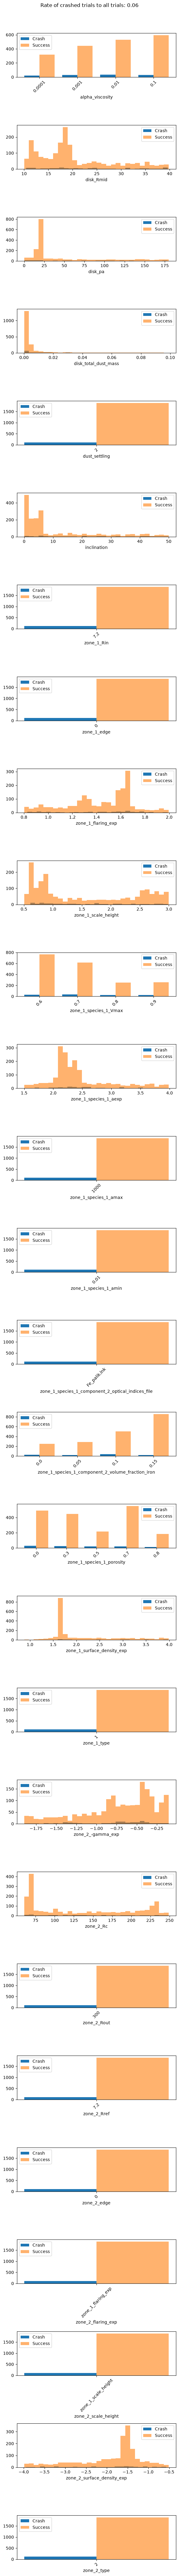

In [48]:

plot_crash_success_histograms(df, crashed_trials, successful_trials, param_cols, results_dir=results_dir, max_unique=20, nbins=30)

### Pairwise sanity checks (parameter vs cost)


[1. 3. 9.]
Processing budget: 1.0


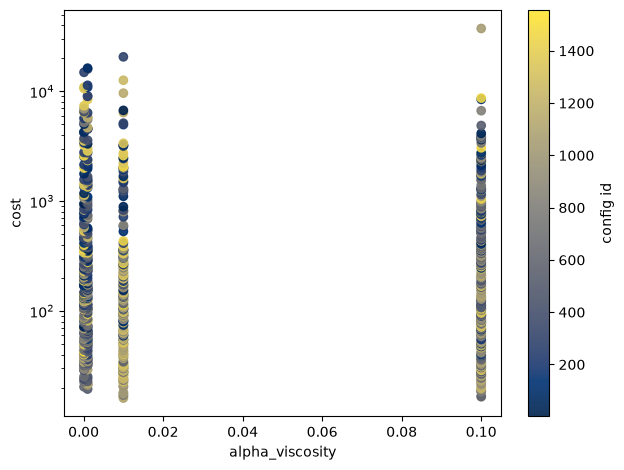

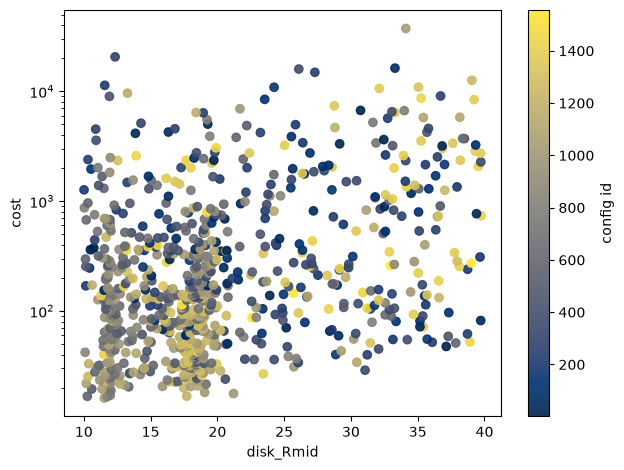

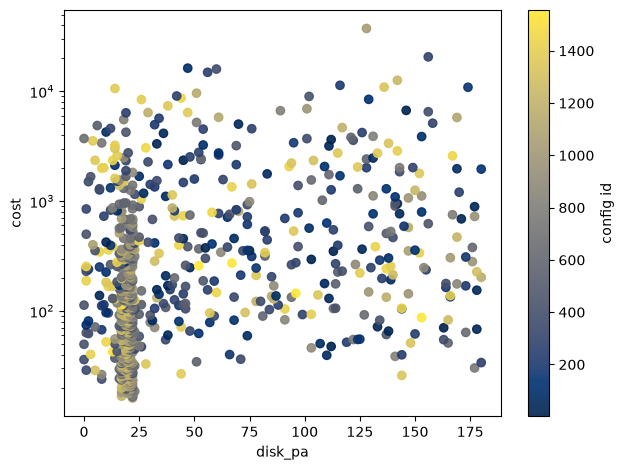

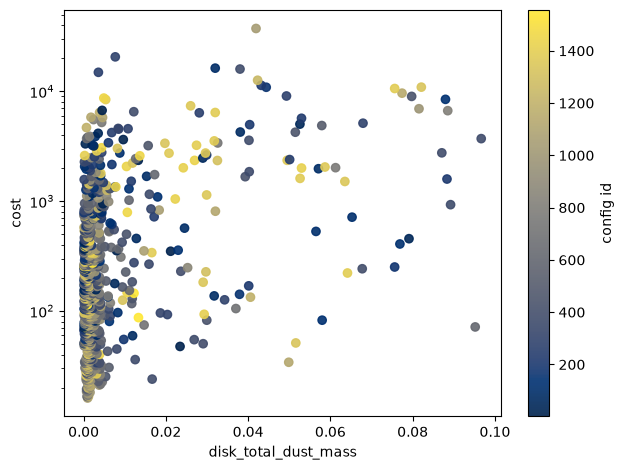

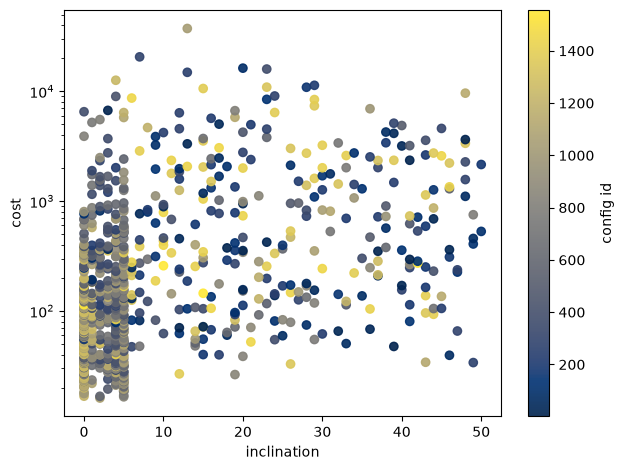

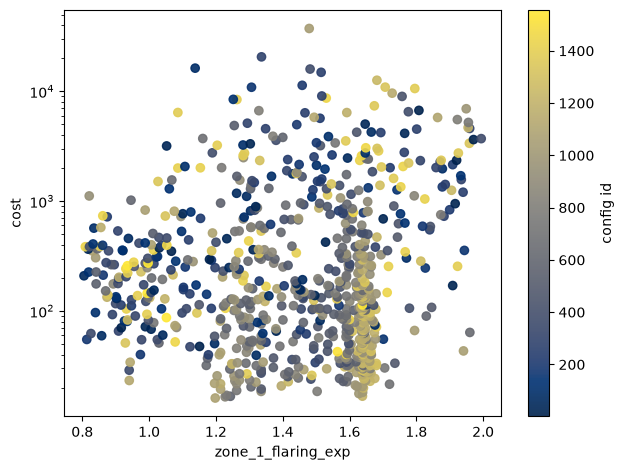

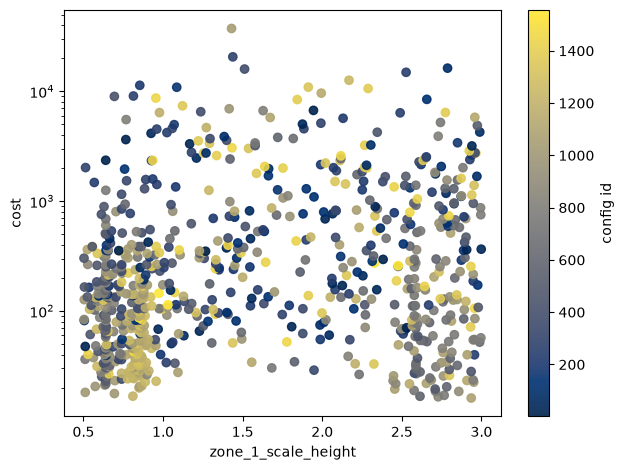

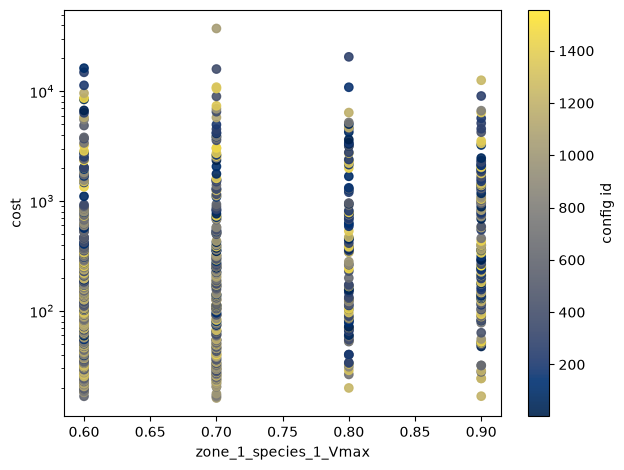

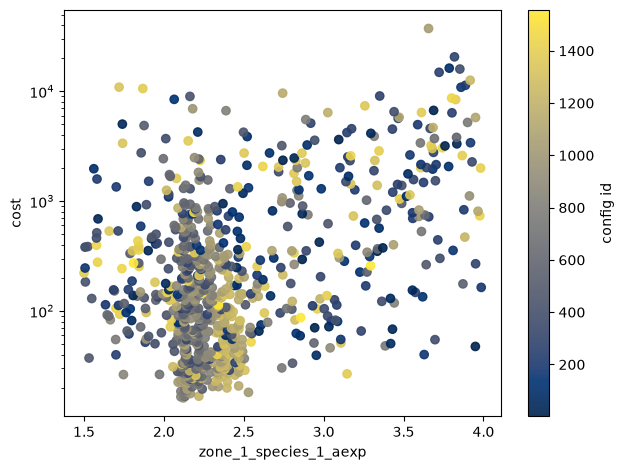

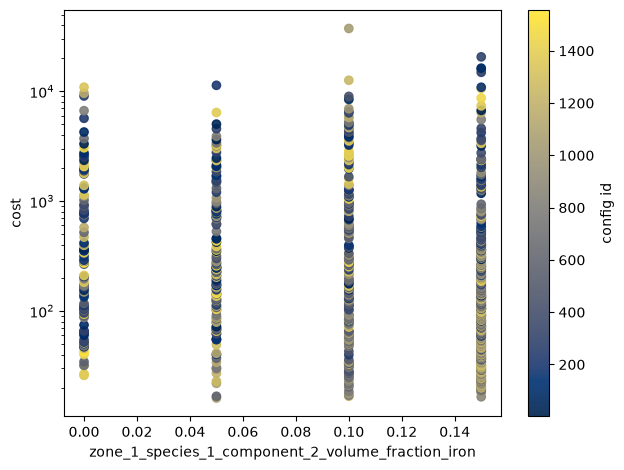

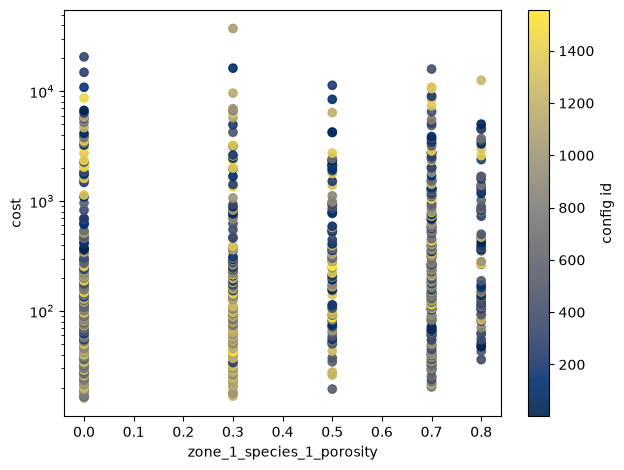

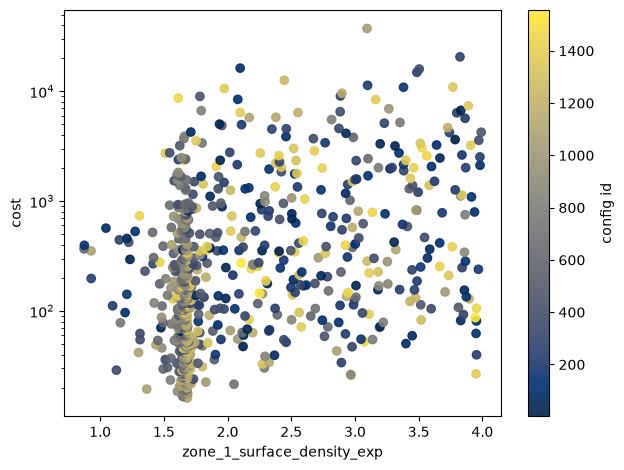

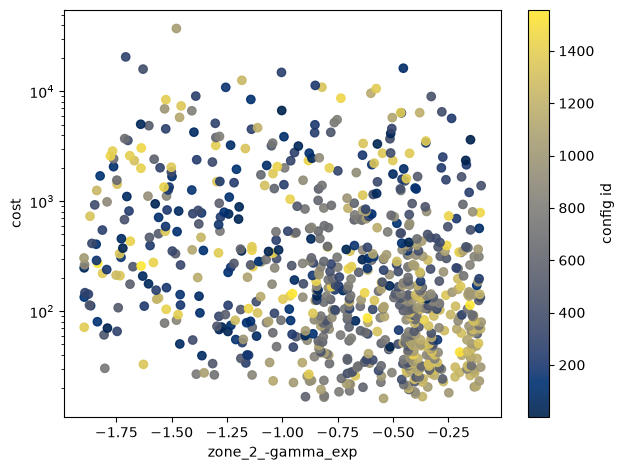

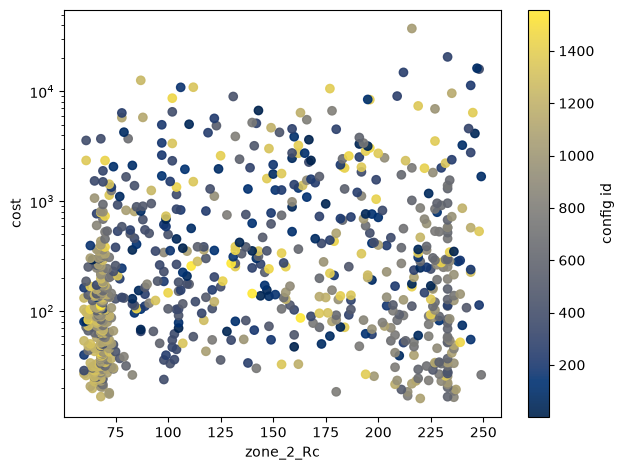

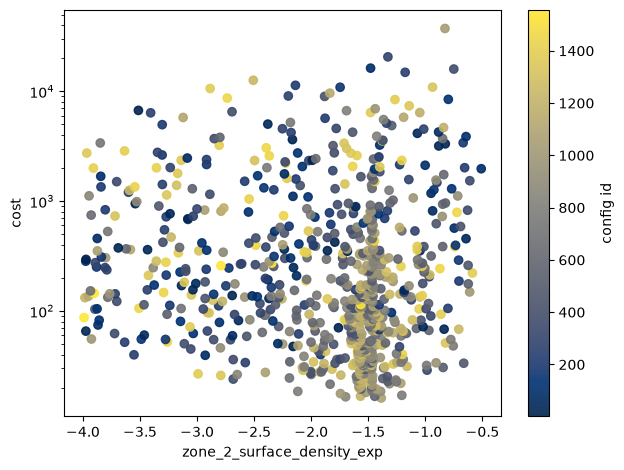

Processing budget: 3.0


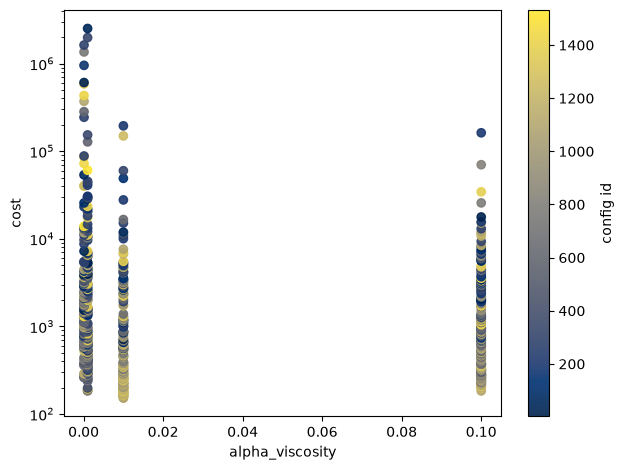

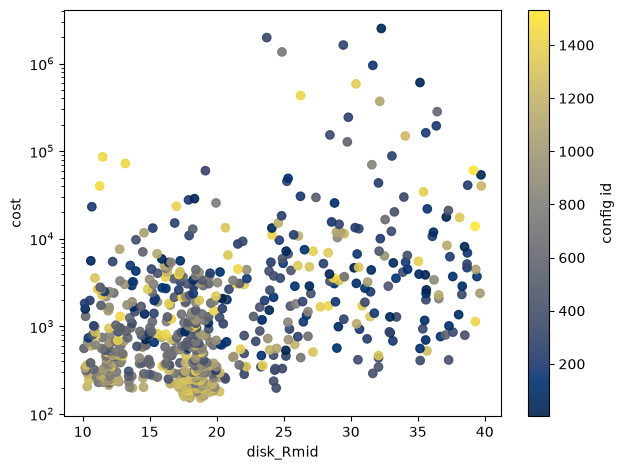

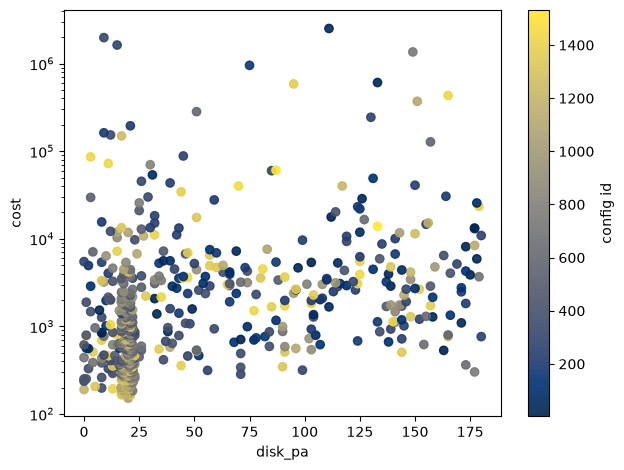

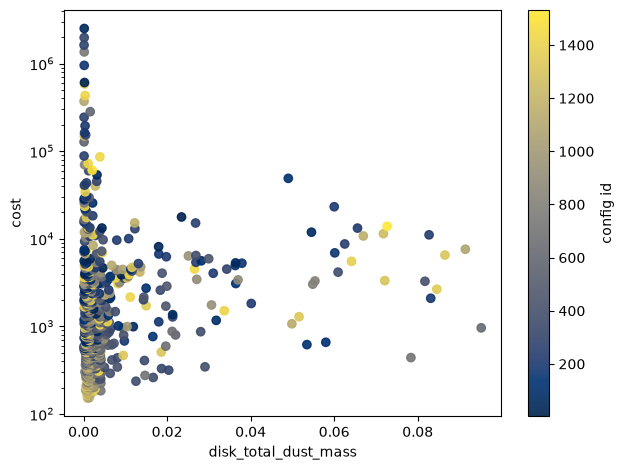

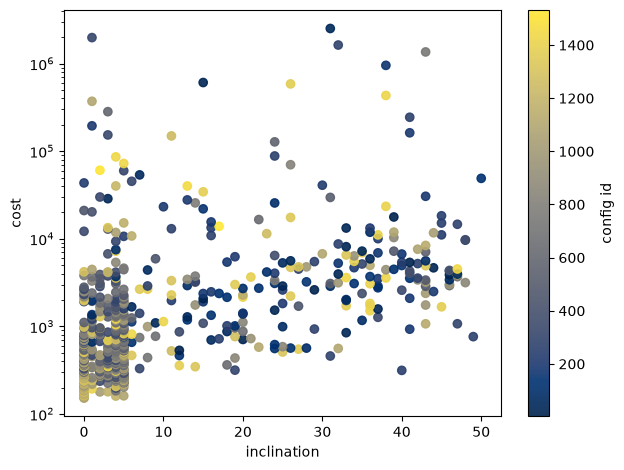

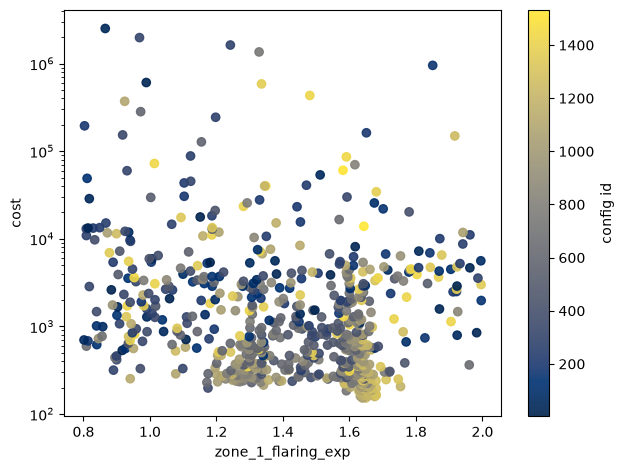

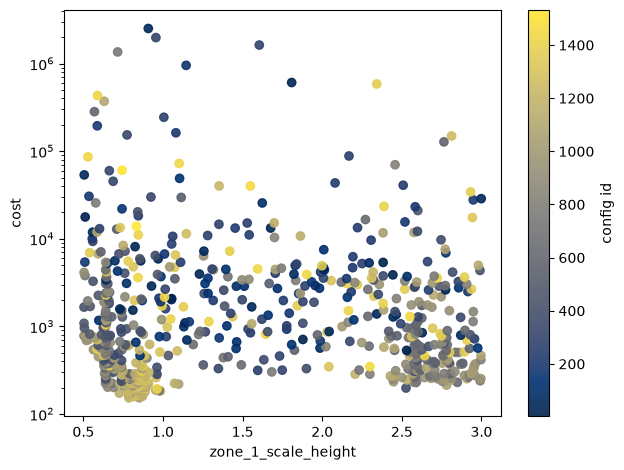

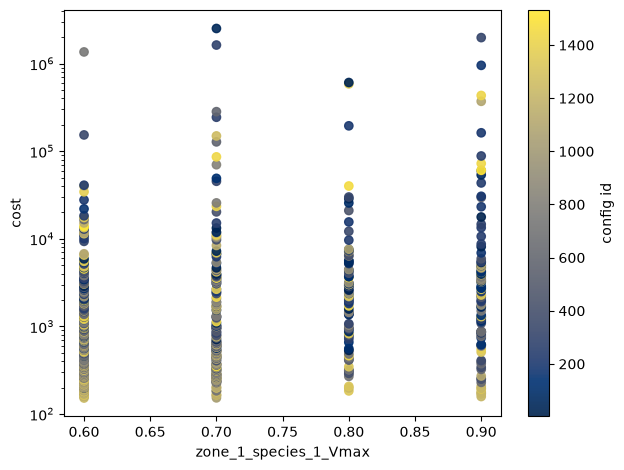

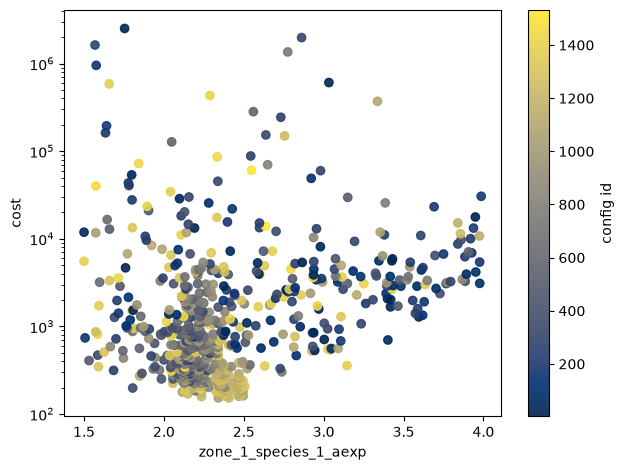

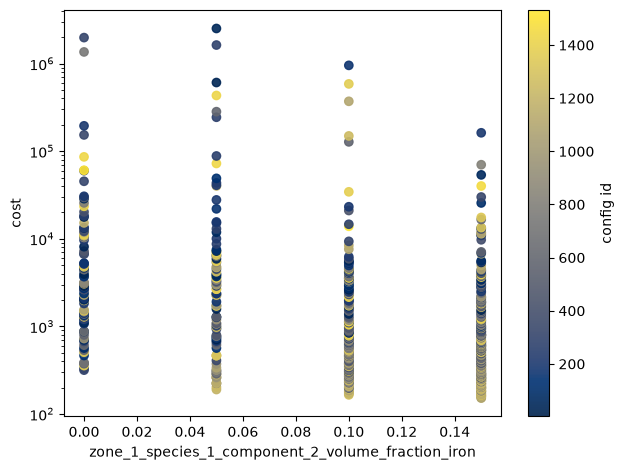

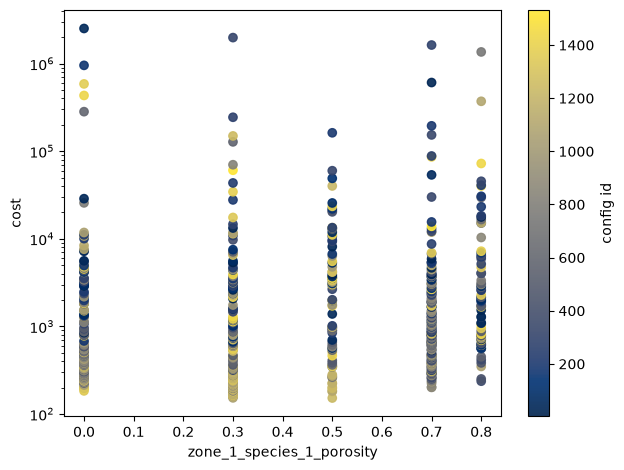

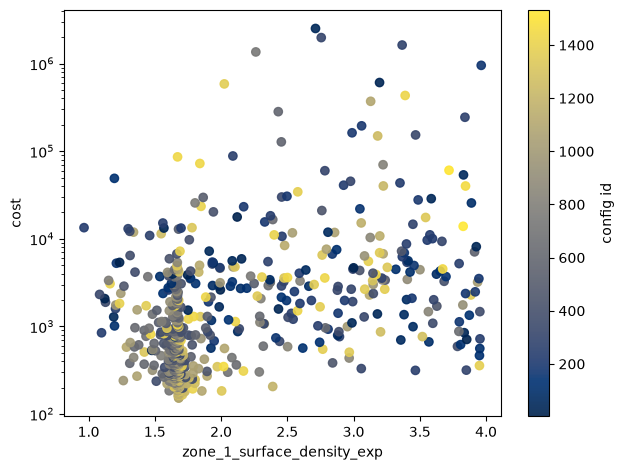

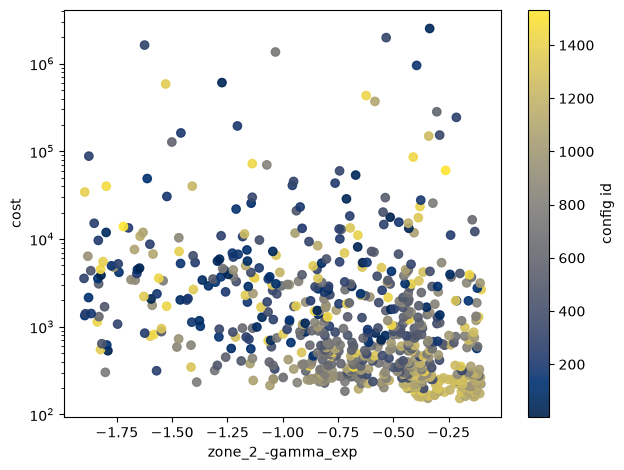

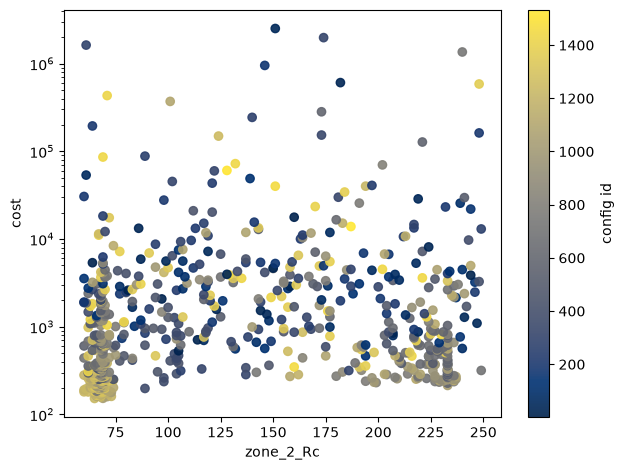

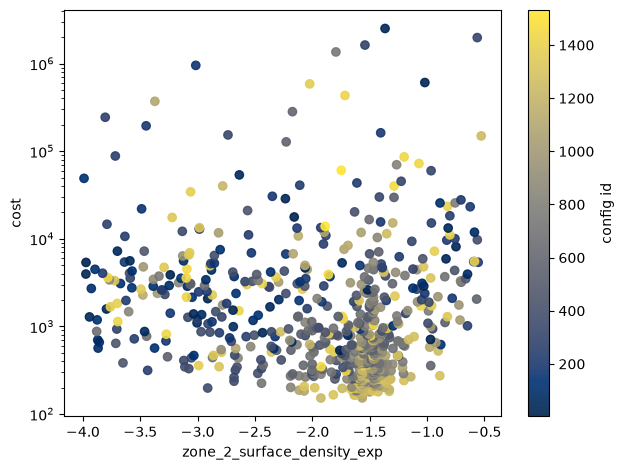

Processing budget: 9.0


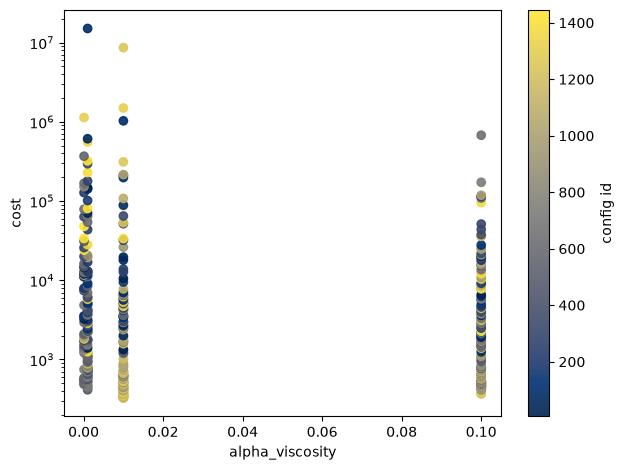

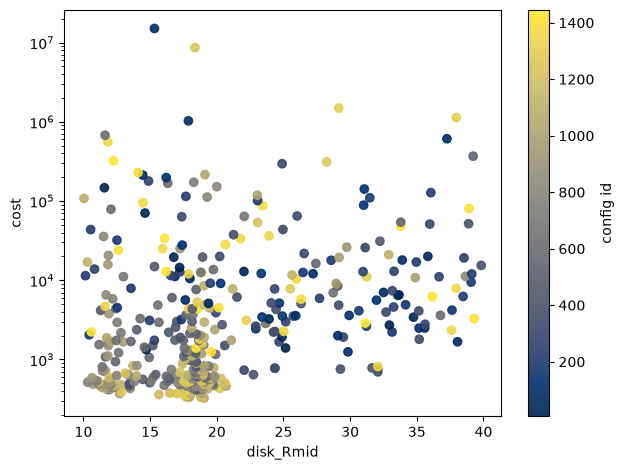

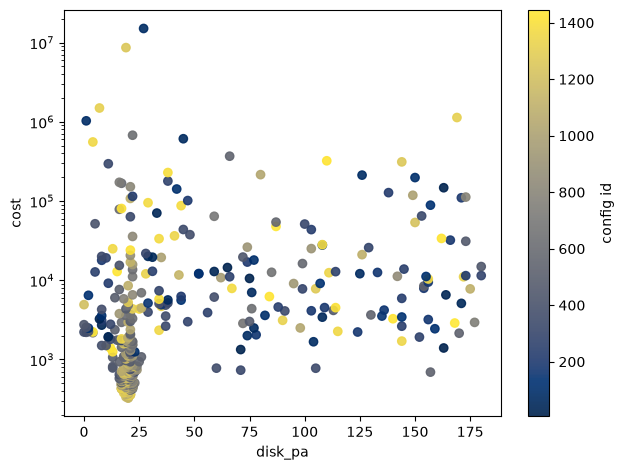

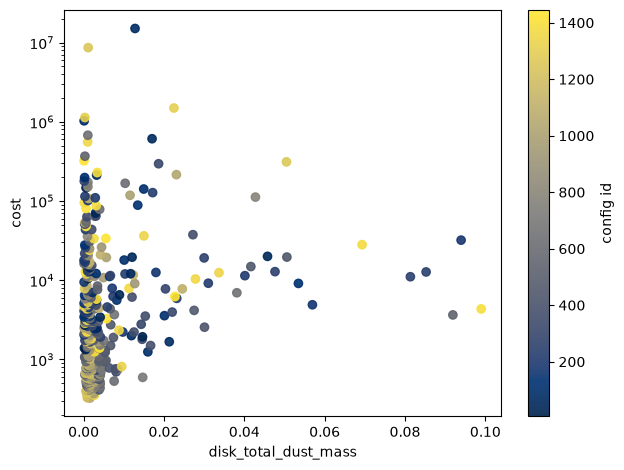

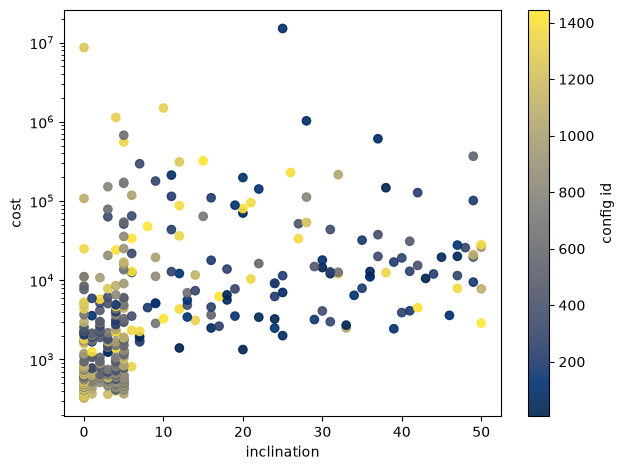

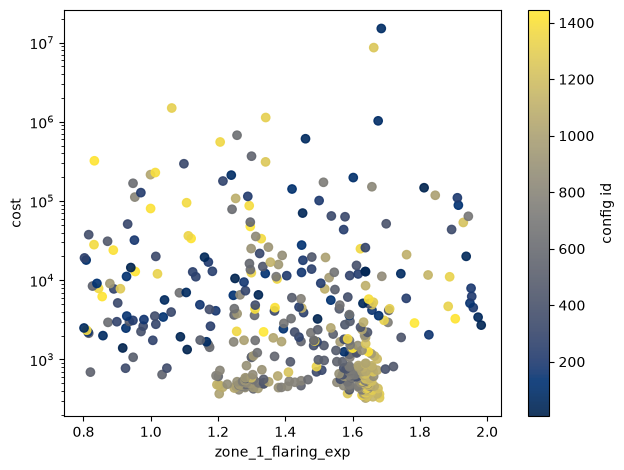

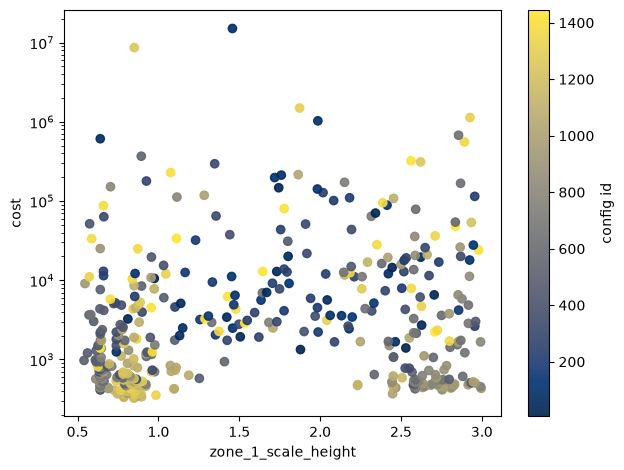

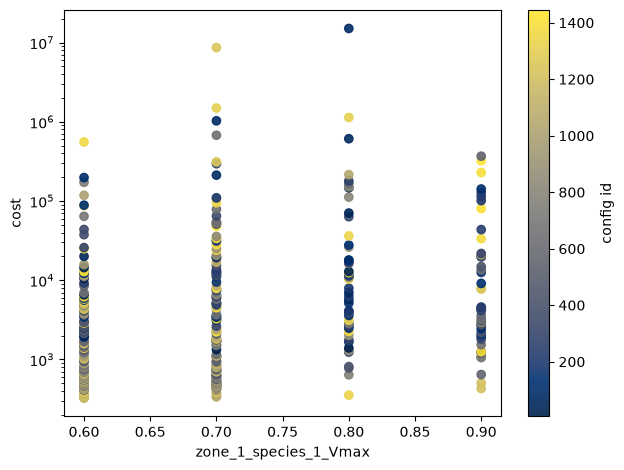

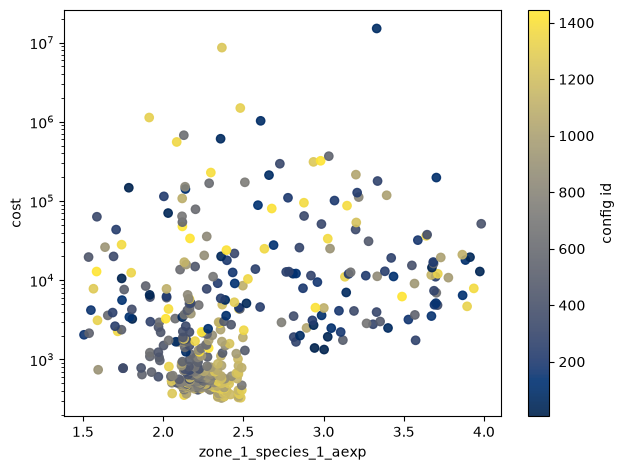

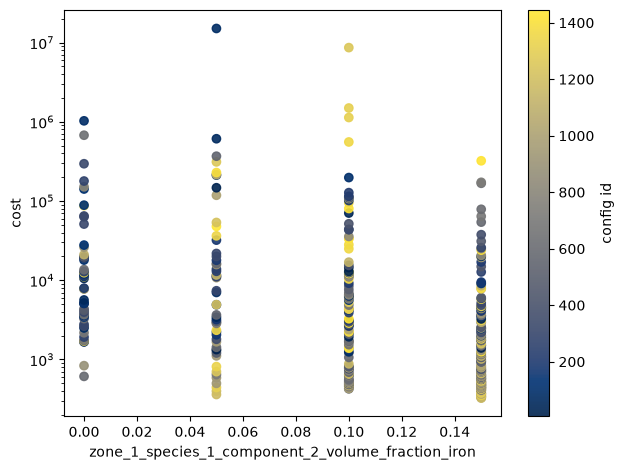

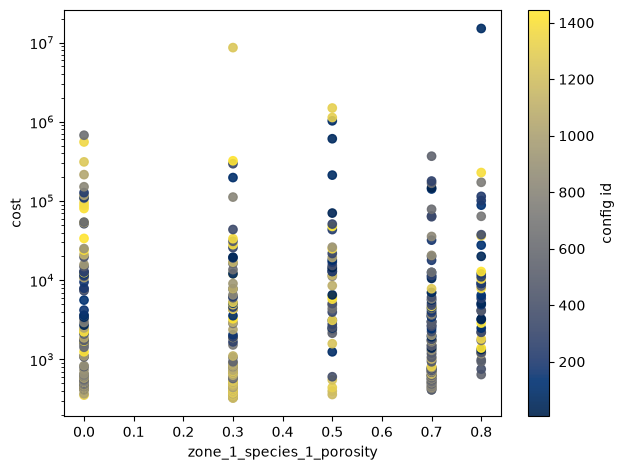

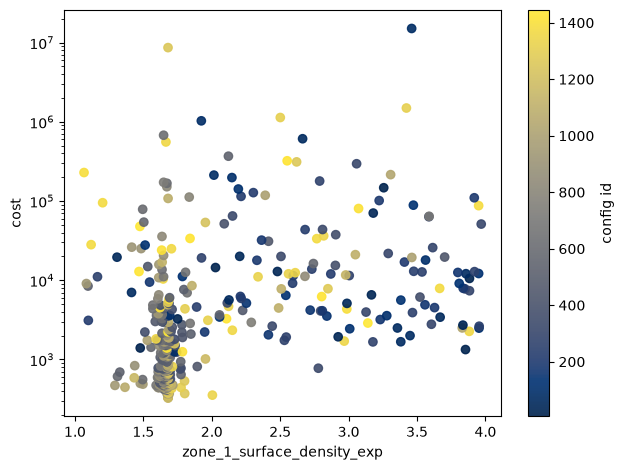

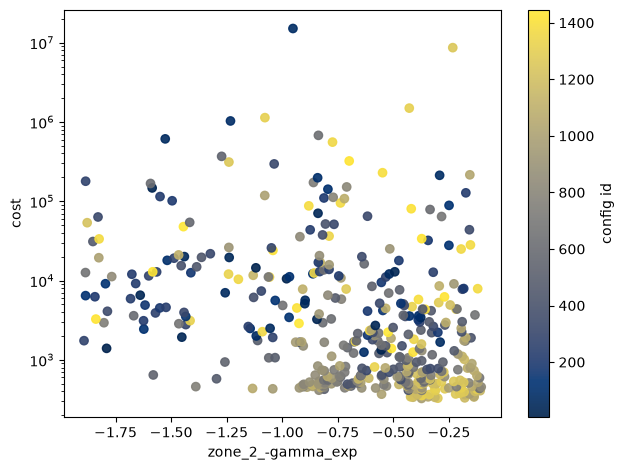

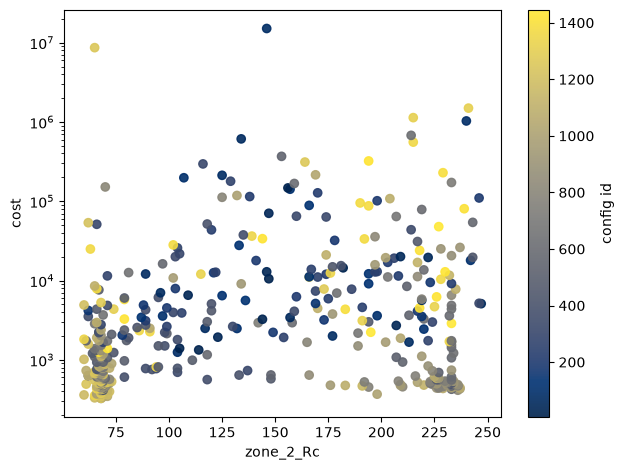

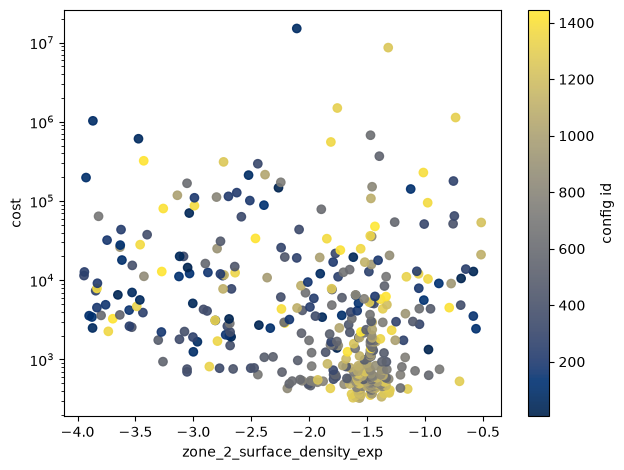

In [49]:
successful_trials=successful_trials[successful_trials['cost'] <1e8]

successful_trials_budget = successful_trials['budget'].unique()


print(successful_trials_budget)
for budget in successful_trials_budget:
    print(f"Processing budget: {budget}")
    successful_trials_budget_df = successful_trials[successful_trials['budget'] == budget]
    for p in param_cols:  # rename to your actual names
        if p in df.columns:
            if successful_trials_budget_df[p].unique().size > 1:
                plt.figure()
                sc=plt.scatter(successful_trials_budget_df[p], successful_trials_budget_df["cost"], c=successful_trials_budget_df["config_id"], cmap='cividis', alpha=0.9)
                plt.xlabel(p)
                plt.ylabel("cost")
                cbar = plt.colorbar(sc)
                cbar.set_label("config id")

                plt.yscale("log")  
                plt.tight_layout()
                plt.savefig(results_dir +f"scatter_{p}_budget_{budget}.png", dpi=150)
                plt.show()
                plt.close()


### Slice by budget (does the story change with fidelity?)

In [50]:
successful_trials.groupby("budget")["cost"].describe()#.to_csv(results_dir / "cost_by_budget.csv")


,count,mean,std,min,25%,50%,75%,max
budget,,,,,,,,
1.0,779.0,887.155147,2376.366799,16.094146,61.780281,155.985879,583.294970,3.735969e+04
3.0,679.0,20767.250250,157124.113700,151.984414,325.240457,793.327757,3067.871519,2.516818e+06
9.0,420.0,85275.737482,853869.556523,325.883644,562.590551,1775.652930,9089.553552,1.507276e+07


### Parameter importance (fast, practical)

In [51]:
def binned_medians(successful_trials, param, bins=2):
    s = successful_trials[[param, "cost"]].dropna()
    s["bin"] = pd.qcut(s[param], q=bins, duplicates="drop")
    return s.groupby("bin", observed=True)["cost"].median().sort_values()

for p in ["zone_1_Rc", "zone_1_flaring_exp", "zone_1_dust_mass", "zone_1_species_1_porosity"]:
    if p in successful_trials.columns:
        bm = binned_medians(successful_trials[successful_trials["budget"] == successful_trials["budget"].max()], p)
        print(f"Binned medians for {p}:")
        print(bm)
        #bm.to_csv(results_dir / f"binned_median_{p}.csv")


Binned medians for zone_1_flaring_exp:
bin
(1.49, 1.983]     915.336999
(0.801, 1.49]    3233.866515
Name: cost, dtype: float64
Binned medians for zone_1_species_1_porosity:
bin
(-0.001, 0.3]     838.370230
(0.3, 0.8]       2994.504991
Name: cost, dtype: float64


### Clustering of “good” solutions (degeneracies)

In [52]:

percent_of_successful = len(successful_trials)*0.1

good = successful_trials[successful_trials["budget"] == successful_trials["budget"].max()].nsmallest(int(percent_of_successful), "cost")
good.describe()#.to_csv(results_dir / "good5_summary.csv")

,alpha_viscosity,disk_Rmid,disk_pa,disk_total_dust_mass,distance_pc,dust_settling,inclination,zone_1_Rin,zone_1_Rref,zone_1_edge,...,zone_2_Rout,zone_2_Rref,zone_2_edge,zone_2_surface_density_exp,zone_2_type,config_id,seed,budget,cost,time
count,187.000000,187.000000,187.000000,187.000000,187.0,187.0,187.000000,1.870000e+02,1.870000e+02,187.0,...,187.0,1.870000e+02,187.0,187.000000,187.0,187.000000,1.870000e+02,187.0,187.000000,187.000000
mean,0.038834,16.766224,22.005348,0.002220,1220.0,2.0,2.427807,7.200000e+00,7.200000e+00,0.0,...,300.0,7.200000e+00,0.0,-1.613337,2.0,872.074866,1.819988e+09,9.0,611.528718,1501.771424
std,0.044915,4.139401,13.284924,0.002162,0.0,0.0,2.503519,2.671688e-15,2.671688e-15,0.0,...,0.0,2.671688e-15,0.0,0.376711,0.0,288.100984,0.000000e+00,0.0,234.462020,627.078917
min,0.000100,10.322184,13.000000,0.000286,1220.0,2.0,0.000000,7.200000e+00,7.200000e+00,0.0,...,300.0,7.200000e+00,0.0,-3.262245,2.0,13.000000,1.819988e+09,9.0,325.883644,698.327882
25%,0.001000,12.744460,19.000000,0.001059,1220.0,2.0,0.000000,7.200000e+00,7.200000e+00,0.0,...,300.0,7.200000e+00,0.0,-1.641081,2.0,675.500000,1.819988e+09,9.0,453.069498,860.275115
50%,0.010000,17.757344,21.000000,0.001372,1220.0,2.0,2.000000,7.200000e+00,7.200000e+00,0.0,...,300.0,7.200000e+00,0.0,-1.503144,2.0,886.000000,1.819988e+09,9.0,529.803166,1378.684405
75%,0.100000,18.899641,21.000000,0.002715,1220.0,2.0,5.000000,7.200000e+00,7.200000e+00,0.0,...,300.0,7.200000e+00,0.0,-1.446782,2.0,1122.500000,1.819988e+09,9.0,712.610995,2192.580795
max,0.100000,32.071724,157.000000,0.015993,1220.0,2.0,20.000000,7.200000e+00,7.200000e+00,0.0,...,300.0,7.200000e+00,0.0,-0.702508,2.0,1408.000000,1.819988e+09,9.0,1333.160369,2615.285905


### Plot

In [53]:
curve = successful_trials.groupby(["config_id", "budget"])["cost"].min().reset_index()
curve#.to_csv(results_dir / "learning_curves.csv", index=False)


,config_id,budget,cost
0,1,1.0,349.634136
1,2,1.0,47.462911
2,2,3.0,17726.021596
3,3,1.0,3635.064360
4,4,1.0,294.587824
...,...,...,...
1873,1552,1.0,113.840798
1874,1553,1.0,257.973686
1875,1554,1.0,272.807099
1876,1555,1.0,86.917423


## For the cornerplot


SMAC does not give a true posterior.
This corner plot represents a high-likelihood region sampled by Bayesian optimisation, not an MCMC posterior.
So... distribution of high-performing models:

In [54]:
# Restrict to highest fidelity
df_max = successful_trials[successful_trials["budget"] == successful_trials["budget"].max()].copy()

# Drop failed / NaN
df_max = df_max.dropna(subset=["cost"])

# Optional: keep only the best 30% of trials
q = 0.9
cost_cut = df_max["cost"].quantile(q)
df_sel = df_max[df_max["cost"] <= cost_cut]


In [55]:
exclude = {"config_id", "seed", "budget", "cost", "time", "status", 
           'distance_pc', "zone_1_Rref"}

param_cols = [c for c in df_sel.columns if c not in exclude]
param_cols


['alpha_viscosity',
 'disk_Rmid',
 'disk_pa',
 'disk_total_dust_mass',
 'dust_settling',
 'inclination',
 'zone_1_Rin',
 'zone_1_edge',
 'zone_1_flaring_exp',
 'zone_1_scale_height',
 'zone_1_species_1_Vmax',
 'zone_1_species_1_aexp',
 'zone_1_species_1_amax',
 'zone_1_species_1_amin',
 'zone_1_species_1_component_2_optical_indices_file',
 'zone_1_species_1_component_2_volume_fraction_iron',
 'zone_1_species_1_porosity',
 'zone_1_surface_density_exp',
 'zone_1_type',
 'zone_2_-gamma_exp',
 'zone_2_Rc',
 'zone_2_Rout',
 'zone_2_Rref',
 'zone_2_edge',
 'zone_2_flaring_exp',
 'zone_2_scale_height',
 'zone_2_surface_density_exp',
 'zone_2_type']

In [56]:
#just one function to do it
#WORKS

def make_corner_plot(
    df,
    params,
    *,
    budget=None,
    best_quantile=0.3,
    title=None,
    outfile="corner.png",
):

    d = df.copy()
    if budget is not None:
        d = d[d["budget"] == budget]

    d = d.dropna(subset=["cost"])
    cost_cut = d["cost"].quantile(best_quantile)
    d = d[d["cost"] <= cost_cut]
    if len(d) == 0:
        print("No data to plot after filtering by budget and cost quantile.")
        return
    params_corner = []
    for p in params:
        if p not in d.columns:
            raise ValueError(f"Parameter '{p}' not found in DataFrame columns.")
        if d[p].unique().size >= 2:
            params_corner.append(p)
        else:
            print(f"Parameter '{p}' has less than 2 unique values in the filtered DataFrame.")


    if len(params_corner) == 0:
        print("No valid parameters to plot after filtering.")
        return
    data = d[params_corner].values

    fig = corner.corner(
        data,
        labels=params_corner,
        quantiles=[0.16, 0.5, 0.84],
        weights=1.0 / d["cost"].values,
        show_titles=True,
        wrap_title_quantiles=True,
        title_fmt=".3g"  
    )
    plt.suptitle(title, fontsize=14, y=1.01)
    fig.savefig(outfile, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)




       zone_1_flaring_exp  zone_1_species_1_porosity
count          378.000000                 378.000000
mean             1.429375                   0.392063
std              0.262098                   0.297898
min              0.801619                   0.000000
25%              1.277306                   0.000000
50%              1.497395                   0.300000
75%              1.637802                   0.700000
max              1.982540                   0.800000


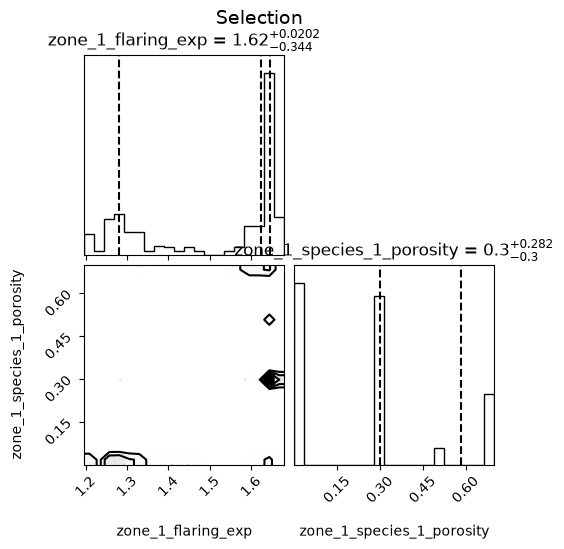

In [57]:
param_cols=[ "zone_1_flaring_exp", "zone_1_species_1_porosity"]
print(df_sel[param_cols].describe())

make_corner_plot(
    df_sel,
    params=param_cols,
    budget=df_sel["budget"].max(),
    outfile=results_dir+ "corner_best.png",
    title="Selection"
)


## setting up subgroups of parameters for corner plots

Parameters for 'Grid setup parameters': []
[]
Parameters for 'Disk orientation parameters': ['disk_pa', 'distance_pc']
Parameter 'distance_pc' has less than 2 unique values in the filtered DataFrame.
['disk_pa']
Parameters for 'Disk geometry parameters': ['disk_Rmid', 'zone_1_Rin', 'zone_1_Rref', 'zone_1_edge', 'zone_1_flaring_exp', 'zone_1_scale_height', 'zone_1_surface_density_exp', 'zone_2_-gamma_exp', 'zone_2_Rc', 'zone_2_Rout', 'zone_2_Rref', 'zone_2_edge', 'zone_2_flaring_exp', 'zone_2_scale_height', 'zone_2_surface_density_exp']
Parameter 'zone_1_Rin' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_1_Rref' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_1_edge' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_2_Rout' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_2_Rref' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_2_edge' has less than 2 unique values 

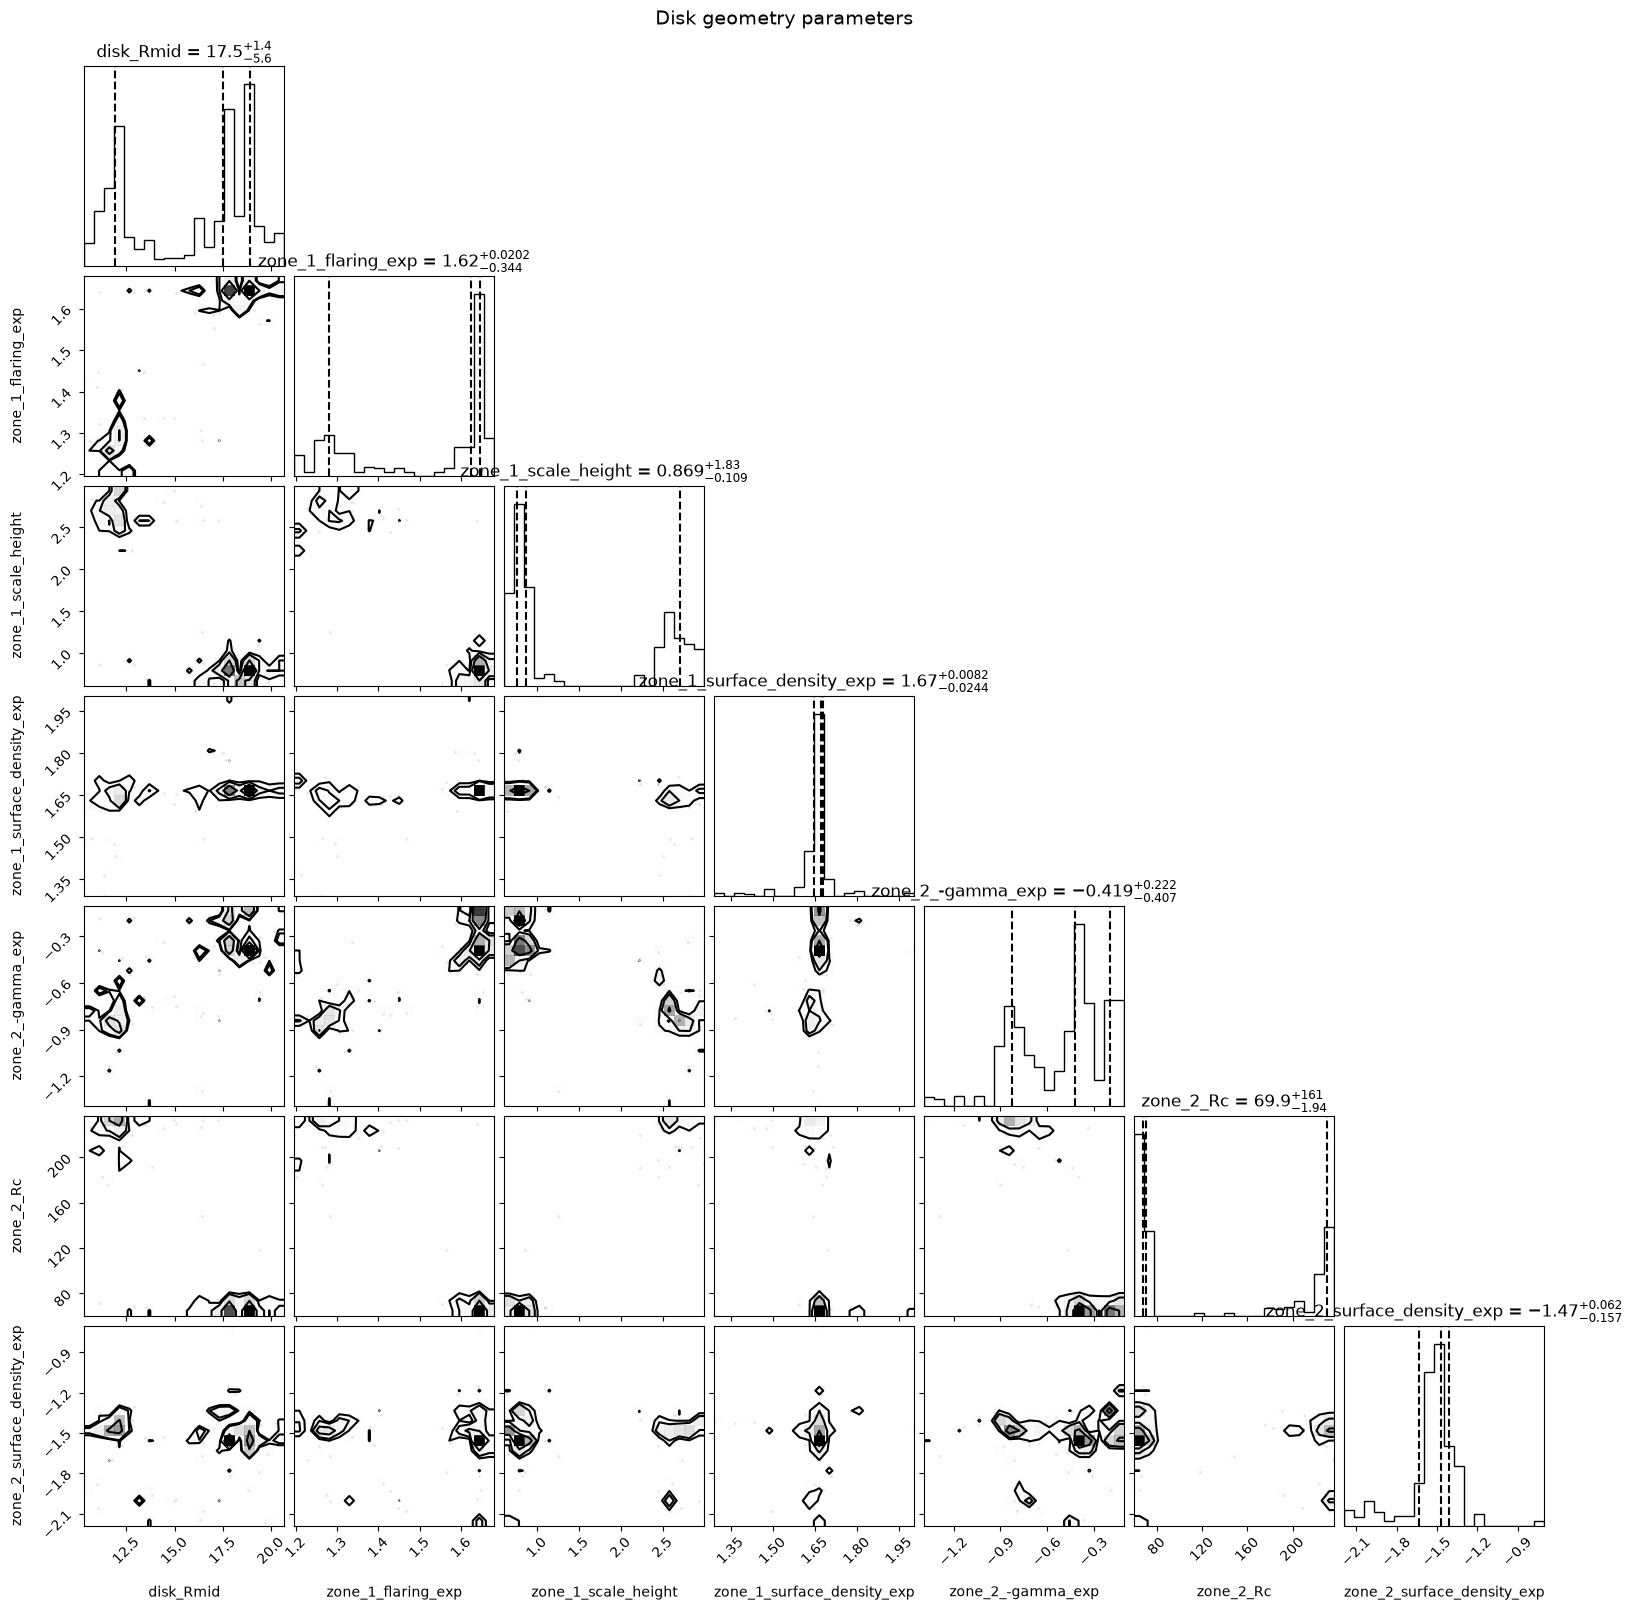

Parameters for 'Dust distribution parameters': ['alpha_viscosity', 'disk_Rmid', 'dust_settling']
Parameter 'dust_settling' has less than 2 unique values in the filtered DataFrame.
['alpha_viscosity', 'disk_Rmid']
Corner plot for Dust distribution parameters:


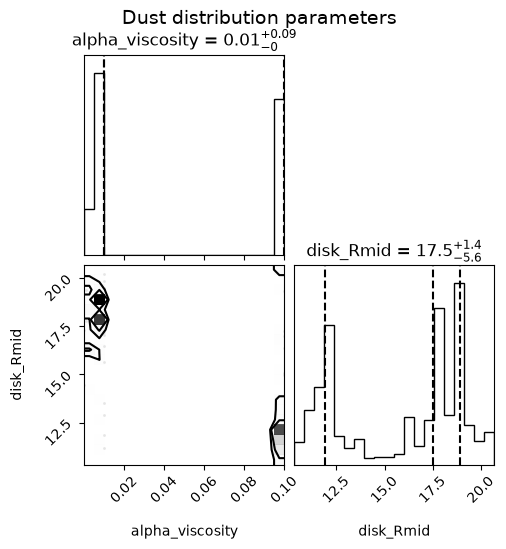

Parameters for 'Dust grain parameters': ['zone_1_species_1_Vmax', 'zone_1_species_1_aexp', 'zone_1_species_1_amax', 'zone_1_species_1_amin', 'zone_1_species_1_porosity']
Parameter 'zone_1_species_1_amax' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_1_species_1_amin' has less than 2 unique values in the filtered DataFrame.
['zone_1_species_1_Vmax', 'zone_1_species_1_aexp', 'zone_1_species_1_porosity']
Corner plot for Dust grain parameters:


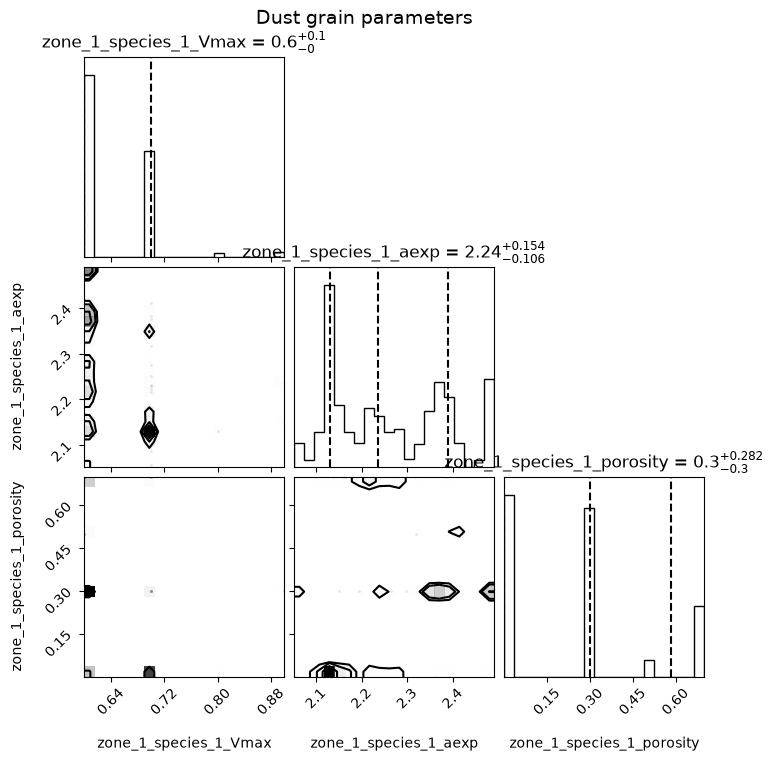

Parameters for 'Star parameters': []
[]


In [58]:
#all parameters

grid_setup_parameters=["grid_geometry", "n_rad", "nz", "n_az", "n_rad_in", "grid_nx", "grid_ny", "grid_size"]
disk_orientation_parameters=["imin", "imax", "n_incl", "centered", "az_min", "az_max", "distance_pc", "disk_pa"]
disk_geometry_parameters=["disk_Rmid","zone_1_scale_height", "zone_1_Rref", "zone_1_vertical_profile_exponent", "zone_1_Rin", "zone_1_edge", "zone_1_Rout", "zone_1_Rc", "zone_1_flaring_exp", "zone_1_surface_density_exp", "zone_1_-gamma_exp", 
                        "zone_2_scale_height", "zone_2_Rref", "zone_2_vertical_profile_exponent", "zone_2_Rin", "zone_2_edge", "zone_2_Rout", "zone_2_Rc", "zone_2_flaring_exp", "zone_2_surface_density_exp", "zone_2_-gamma_exp"]

dust_distribution_parameters=["dust_settling", "exp_strat", "a_strat", "dust_radial_migration", "sublimate_dust", "hydrostatic_equilibrium", "viscous_heating", "alpha_viscosity",
                          "zone_1_dust_mass","zone_2_dust_mass", "disk_Rmid", "zone_1_gas_to_dust"]
dust_grain_parameters=["zone_1_species_1_grain_type", "zone_1_species_1_N_components", "zone_1_species_1_mixing_rule", "zone_1_species_1_porosity", "zone_1_species_1_mass_fraction", "zone_1_species_1_Vmax", "zone_1_species_1_optical_indices_file", "zone_1_species_1_volume_fraction", "zone_1_species_1_heating_method",
                       "zone_1_species_1_amin", "zone_1_species_1_amax", "zone_1_species_1_aexp", "zone_1_species_1_n_grains"]
star_parameters=["star_1_Temp", "star_1_R", "star_1_M", "star_1_x", "star_1_y", "star_1_z", "star_1_autometic_spectrum", "star_1_spectrum_file", "star_1_fUV", "star_1_slope_fUV"]  


titles={"Grid setup parameters": grid_setup_parameters,
        "Disk orientation parameters": disk_orientation_parameters,
        "Disk geometry parameters": disk_geometry_parameters,
        "Dust distribution parameters": dust_distribution_parameters,
        "Dust grain parameters": dust_grain_parameters,
        "Star parameters": star_parameters}

for title in titles.keys():
    param_subset = titles[title]
    param_cols_set = [c for c in df_sel.columns if c in param_subset]
    param_cols_corner = []  # Initialize a list to keep track of parameters with less than 2 unique values
    print(f"Parameters for '{title}': {param_cols_set}")
    for p in param_cols_set:
        if df_sel[p].unique().size >= 2:
            param_cols_corner.append(p) 
        else:
            print(f"Parameter '{p}' has less than 2 unique values in the filtered DataFrame.")

    print(param_cols_corner)

    if len(param_cols_corner)>1:
        print(f"Corner plot for {title}:")
        
        #print(df_sel[param_cols_set].describe())

        make_corner_plot(
            df_sel,
            params=param_cols_corner,
            budget=df_sel["budget"].max(),
            title=title,
            outfile=results_dir+ f"corner_{title}_best.png"
        )

